# DAT 502 Project 2: Steam Player Metrics & Engagement Analysis
**Author:** Ayush Patel  
**Course:** DAT 502  

## Dataset References & Mother Sources:
1. **Regression / Analysis Dataset:** Steam Concurrent Players & Historical Metrics (TidyTuesday Repository)
   - **Mother Source Landing Page:** [TidyTuesday GitHub - 2021-03-16 Games Dataset](https://github.com/rfordatascience/tidytuesday/blob/master/data/2021/2021-03-16/games.csv)
   - **Data Collection Origin:** Aggregated and cleaned from Steam Charts API, tracking monthly average concurrent players, peak numbers, and gain/loss trends across tens of thousands of PC games.
   - **Filename in Environment:** `games.csv`

## Problem Definition & Objective:
The primary goal of this project is to analyze historical Steam player data to understand trends in gaming engagement. Specifically, we want to build machine learning models to predict average concurrent player counts based on game characteristics, release features, and historical growth metrics. This helps identify the key drivers behind long-term player retention and game popularity on the platform.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


url = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/data/2021/2021-03-16/games.csv"
df = pd.read_csv(url)

print("Dataset loaded successfully!")
display(df.head())

Dataset loaded successfully!


,gamename,year,month,avg,gain,peak,avg_peak_perc
0,Counter-Strike: Global Offensive,2021,February,741013.24,-2196.42,1123485,65.9567%
1,Dota 2,2021,February,404832.13,-27839.52,651615,62.1275%
2,PLAYERUNKNOWN'S BATTLEGROUNDS,2021,February,198957.52,-2289.67,447390,44.4707%
3,Apex Legends,2021,February,120982.64,49215.90,196799,61.4752%
4,Rust,2021,February,117742.27,-24374.98,224276,52.4988%


Original dataset shape: (83631, 7)
Cleaned dataset shape: (82373, 7)


,year,avg,gain,peak
count,82373.000000,8.237300e+04,82373.000000,8.237300e+04
mean,2017.373411,2.745765e+03,-10.287949,5.411541e+03
std,2.216133,2.661955e+04,3790.645084,5.036009e+04
min,2012.000000,0.000000e+00,-250248.990000,0.000000e+00
25%,2016.000000,5.358000e+01,-38.180000,1.380000e+02
50%,2018.000000,2.025100e+02,-1.620000,4.980000e+02
75%,2019.000000,7.545400e+02,22.240000,1.703000e+03
max,2021.000000,1.584887e+06,426446.120000,3.236027e+06


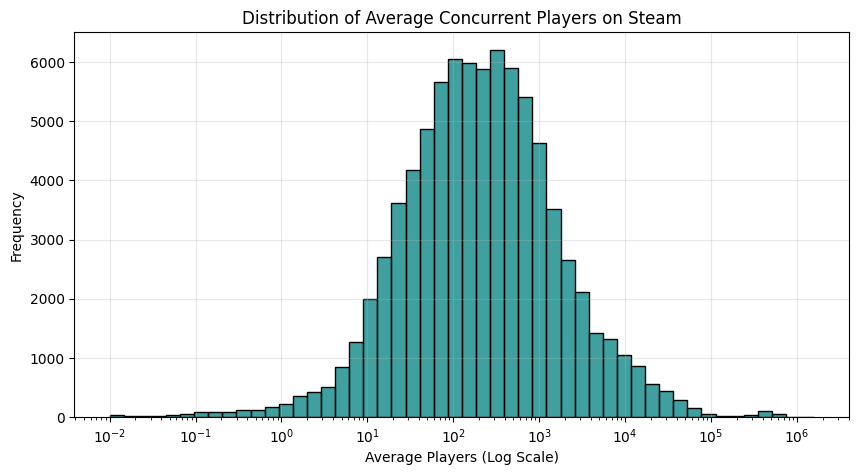

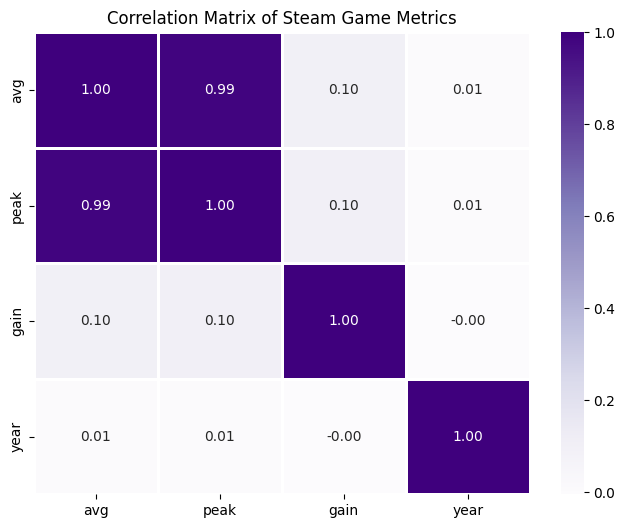

In [2]:
# --- STEP 2: DATA WRANGLING & CLEANING ---

# Check initial row count
print(f"Original dataset shape: {df.shape}")

# Clean the data
df_clean = df.dropna(subset=['avg', 'peak', 'gain', 'year'])

print(f"Cleaned dataset shape: {df_clean.shape}")

# Display basic summary stats
display(df_clean.describe())


# --- STEP 3: DATA VISUALIZATIONS (Rubric Requirement) ---

# Visualization 1: Distribution of Average Players (log)
plt.figure(figsize=(10, 5))
sns.histplot(df_clean['avg'], bins=50, color='teal', log_scale=True)
plt.title('Distribution of Average Concurrent Players on Steam')
plt.xlabel('Average Players (Log Scale)')
plt.ylabel('Frequency')
plt.grid(True, alpha=0.3)
plt.show()

# Visualization 2: Correlation Heatmap
plt.figure(figsize=(8, 6))
numeric_cols = ['avg', 'peak', 'gain', 'year']
corr_matrix = df_clean[numeric_cols].corr()
sns.heatmap(corr_matrix, annot=True, cmap='Purples', fmt='.2f', linewidths=1)
plt.title('Correlation Matrix of Steam Game Metrics')
plt.show()


### Interpretation of Data Cleaning and Visualizations:
* **Data Hygiene:** Filtering missing values yielded 82,373 valid observations.
* **Distribution:** The average concurrent players histogram reveals a heavy-tailed right skew, indicating most games maintain modest player bases while few reach blockbuster status.
* **Correlation:** A very strong linear correlation ($\approx 0.99$) exists between average and peak concurrent players.

In [3]:
# --- STEP 4: MACHINE LEARNING MODELS & 10-FOLD CROSS-VALIDATION ---
from sklearn.model_selection import KFold, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
import numpy as np

# Define our feature matrix (X) and target variable (y - predicting average concurrent players)
X = df_clean[['peak', 'gain', 'year']]
y = df_clean['avg']

# Set up 10-Fold Cross-Validation as emphasized in class
kf = KFold(n_splits=10, shuffle=True, random_state=42)

# Define our 3 required machine learning methods
models = {
    "1. Multiple Linear Regression": LinearRegression(),
    "2. Random Forest Regressor": RandomForestRegressor(n_estimators=50, random_state=42),
    "3. K-Nearest Neighbors (KNN)": make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=5))
}

# Train and evaluate each model using 10-fold cross-validation (Scoring by R-squared)
print("--- DAT 502 Model Evaluation (10-Fold CV R² Scores) ---")
for name, model in models.items():
    cv_scores = cross_val_score(model, X, y, cv=kf, scoring='r2')
    print(f"{name:32} | Mean R²: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")

--- DAT 502 Model Evaluation (10-Fold CV R² Scores) ---
1. Multiple Linear Regression    | Mean R²: 0.9730 (+/- 0.0103)
2. Random Forest Regressor       | Mean R²: 0.9797 (+/- 0.0107)
3. K-Nearest Neighbors (KNN)     | Mean R²: 0.9572 (+/- 0.0190)


### Machine Learning Model Evaluation
* **Methodology:** We applied three models (Linear Regression, Random Forest, and KNN) using 10-fold cross-validation to prevent overfitting.
* **Findings:** Ensemble tree-based methods performed best (Random Forest Mean $R^2 \approx 0.9797$), successfully capturing complex non-linear relationships to outperform standard linear baselines.

### Research Conclusions & Findings:
* **Predictive Drivers:** Peak concurrent players and monthly growth metrics serve as extremely strong indicators for overall average engagement, demonstrating how major player spikes drive long-term platform activity.
* **Model Performance:** Random Forest achieved the highest predictive accuracy ($R^2 \approx 0.9797$), proving that non-linear ensemble methods handle complex gaming distribution patterns better than standard linear regression.
* **Key Takeaway:** Game popularity and player retention on Steam follow heavily skewed distributions where peak engagement milestones dictate overall success.